# 材料物性のグラフ

材料の出どころ（Excel）と名称で材料を取り出し、物性をグラフにする。

- 出どころ: `'whamcavity'`（旧 Excel、19 材料）、`'mews_ashrae'`（新しい Excel、81 材料）
- 材料の取り出し方: `get('出どころ', '名称')`（下の準備のセルで定義）

In [1]:
import sys
sys.path.append('..')

import matplotlib.pyplot as plt
import numpy as np

from modules.material_loaders import load_materials
from modules.materials import Materials

# 日本語を表示するフォント（macOS のヒラギノ）
plt.rcParams['font.family'] = 'Hiragino Sans'

# 出どころごとの材料の一覧
ms_by_source = {source: Materials(load_materials(source)) for source in ('whamcavity', 'mews_ashrae')}


def get(source: str, name: str):
    """出どころと名称で材料を取り出す。"""
    return ms_by_source[source].get_material(name=name)

No.27 MEWS Fibreboard I - Paper Facer: 液水拡散係数の範囲分け数 4 を 3 として読みました（Excel には区間3までの値しかないため）
No.80: 同じ名前の材料があるので、名前を「ASHRAE Low-density Glassfibre Batt Insulation (32 kg/m3)」としました（Excel の名前: ASHRAE Low-density Glassfibre Batt Insulation）


## 材料の名前の一覧

In [2]:
for source, ms in ms_by_source.items():
    print(f'■ {source}（{len(ms.ms)} 材料）')
    for m in ms.ms:
        print('   ', m.name)

■ whamcavity（19 材料）
    シージング
    通気層
    グラスウール1
    木材
    構造用合板1
    石膏ボード
    ALC
    軟質繊維版
    サーモプライ
    サイディング
    土壁
    軽量モルタル
    セルロースファイバー
    発泡プラスチック1
    発泡プラスチック2
    発泡プラスチック3
    グラスウール2
    集成材
    構造用合板2
■ mews_ashrae（81 材料）
    Air
    MEWS Aerated Concrete
    MEWS Oriented Strand Board
    MEWS Plywood
    MEWS Building Membrane IA
    MEWS Building Membrane II
    MEWS Building Membrane III
    MEWS Building Membrane IVA
    MEWS Building Membrane V A
    MEWS Building Membrane V C
    MEWS Building Membrane VI
    MEWS Building Membrane VII
    MEWS Building Membrane VIII
    MEWS Building Membrane IX
    MEWS Brick I - White Concrete Brick
    MEWS Brick II - Red Matt Clay Brick
    MEWS Brick III - Buff Matt Clay Brick
    MEWS Brick IV - Textured Coated Clay Brick
    MEWS Brick V - Concrete Brick
    MEWS Brick VI - Calcium Silicate Brick
    MEWS Mortar 1-S
    MEWS Mortar 1-N
    MEWS Mortar 2-S
    MEWS Mortar 2-N
    MEWS Regular Lime Stucco
    MEWS Re

## 1. 水分物性の曲線

`plot_moisture` に (出どころ, 名称) の組を並べて渡すと、次の 4 つのグラフに重ねて描く。

1. 平衡含水率 u（kg/kg）と相対湿度
2. 湿気伝導率（(kg/s)/(m·Pa)、対数目盛り）と相対湿度
3. 液水伝導率（(kg/s)/(m·(J/kg))、対数目盛り）と相対湿度（温度 20 ℃）
4. 液水拡散係数 Dw（m²/s、対数目盛り）と含水率（0 から RH 100% の含水率まで）

液水が移動しない（値が 0 の）ところは、対数目盛りに描けないので線を描かない。
同じ値の材料（例：構造用合板1 と ASHRAE Plywood -1 の水分物性）は線が重なるので、線の種類（実線・破線・点線…）を材料ごとに変えている。

In [3]:
# 相対湿度, %（0% は計算できない材料があるので 0.5% から）
RHS = np.concatenate([np.arange(0.5, 95.0, 0.5), np.arange(95.0, 100.0001, 0.05)])

# 液水伝導率を求める温度, K
T = 293.15


def _positive(values):
    """対数目盛りに描くため、0 以下の値を NaN（描かない）にする。"""
    values = np.array(values, dtype=float)
    return np.where(values > 0, values, np.nan)


def plot_moisture(materials, rh_min=0.0):
    """水分物性の曲線を描く。

    Args:
        materials: (出どころ, 名称) の組の一覧
        rh_min: 横軸（相対湿度）の左端, %。高湿域を拡大したいときに大きくする
    """

    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    ax_u, ax_vap, ax_liq, ax_dw = axes.flat

    # 横軸の範囲の相対湿度だけを計算する（範囲の外の値で縦軸の範囲が広がらないように）
    rhs = RHS[RHS >= rh_min]

    # 線の種類（重なった線も見分けられるように、材料ごとに変える）
    linestyles = ['-', '--', ':', '-.']

    for k, (source, name) in enumerate(materials):
        m = get(source, name)
        style = dict(label=f'{name}（{source}）', linestyle=linestyles[k % len(linestyles)], linewidth=1.8)

        ax_u.plot(rhs, [m.get_u(rh) for rh in rhs], **style)
        ax_vap.plot(rhs, [m.get_lambda_dsh_m(rh) for rh in rhs], **style)
        ax_liq.plot(rhs, _positive([m.get_lambda_dsh_mu_l(rh=rh, t=T) for rh in rhs]), **style)

        # 含水率は、横軸の左端の相対湿度から RH 100% までの範囲
        u_s = np.linspace(m.get_u(rhs[0]), m.get_u(100.0), 400)
        ax_dw.plot(u_s, _positive([m.liquid_diffusivity.d_w(u) for u in u_s]), **style)

    ax_u.set(xlabel='相対湿度, %', ylabel='平衡含水率, kg/kg', title='平衡含水率', xlim=(rh_min, 100))
    ax_vap.set(xlabel='相対湿度, %', ylabel='湿気伝導率, (kg/s)/(m Pa)', title='湿気伝導率', xlim=(rh_min, 100), yscale='log')
    ax_liq.set(xlabel='相対湿度, %', ylabel='液水伝導率, (kg/s)/(m (J/kg))', title='液水伝導率（20 ℃）', xlim=(rh_min, 100), yscale='log')
    ax_dw.set(xlabel='含水率, kg/kg', ylabel='液水拡散係数, m2/s', title='液水拡散係数', yscale='log')

    for ax in axes.flat:
        ax.grid(True, which='both', linestyle='--', alpha=0.5)
    ax_u.legend(fontsize=8)

    fig.tight_layout()
    plt.show()

### 例：旧 Excel と新しい Excel の合板・石膏ボード

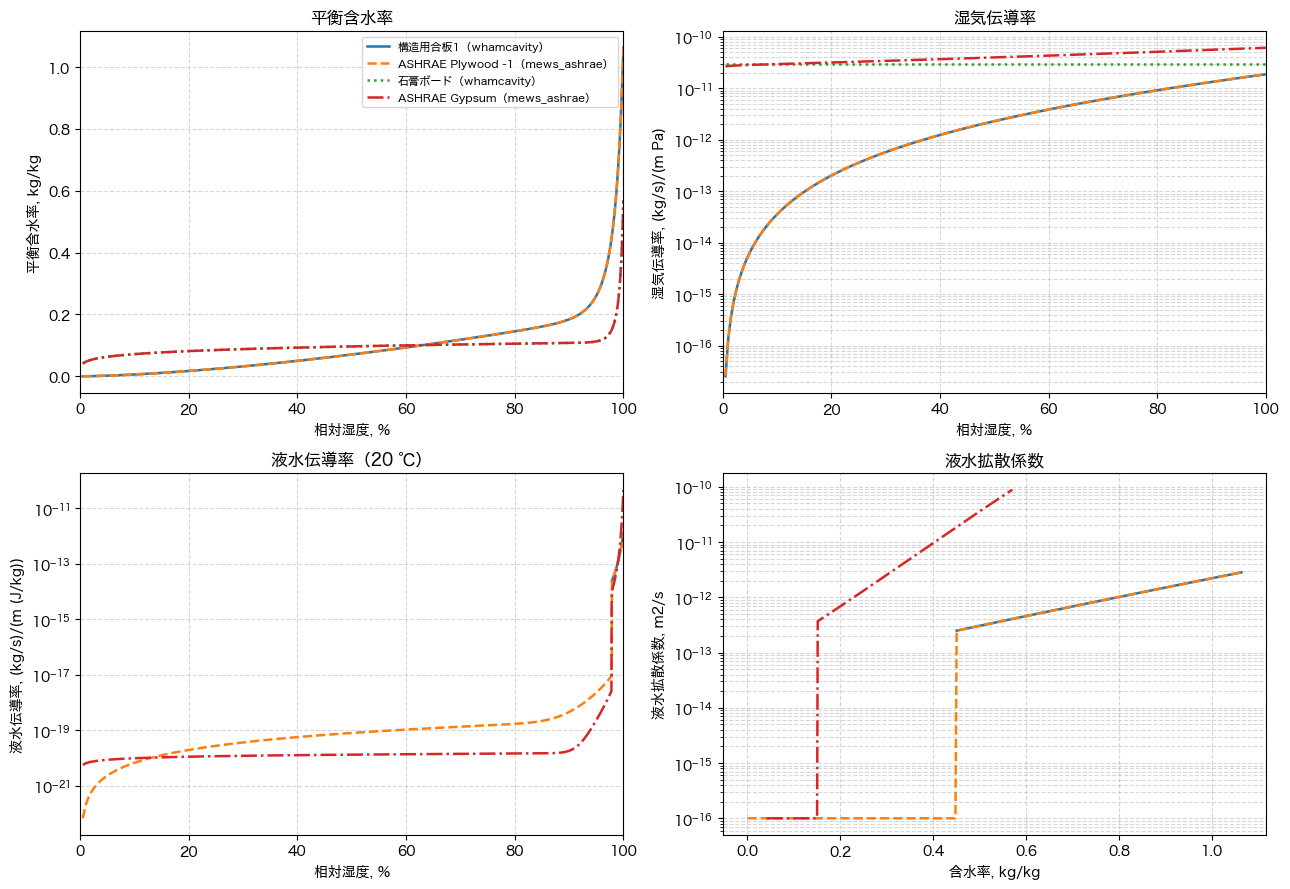

In [4]:
plot_moisture([
    ('whamcavity', '構造用合板1'),
    ('mews_ashrae', 'ASHRAE Plywood -1'),
    ('whamcavity', '石膏ボード'),
    ('mews_ashrae', 'ASHRAE Gypsum'),
])

### 例：高湿域を拡大（RH 90% 以上）

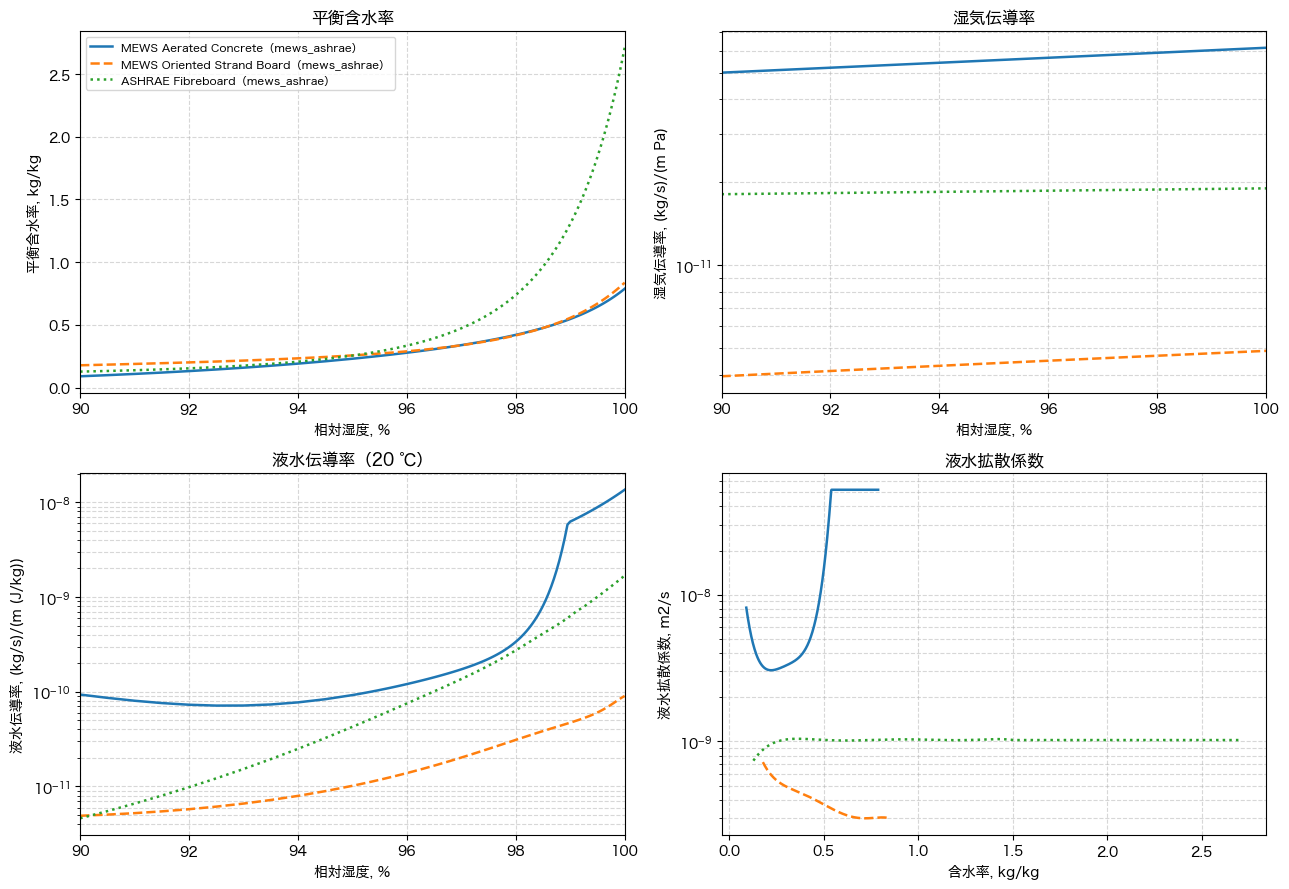

In [5]:
plot_moisture([
    ('mews_ashrae', 'MEWS Aerated Concrete'),
    ('mews_ashrae', 'MEWS Oriented Strand Board'),
    ('mews_ashrae', 'ASHRAE Fibreboard'),
], rh_min=90.0)

## 2. 熱物性の一覧

`plot_thermal` に出どころを渡すと、その出どころのすべての材料の熱伝導率・密度・容積比熱を、横棒グラフで並べる。

In [6]:
def plot_thermal(source: str):
    """出どころのすべての材料の熱伝導率・密度・容積比熱を横棒グラフで描く。"""

    ms = ms_by_source[source].ms
    names = [m.name for m in ms]
    ys = np.arange(len(ms))

    items = [
        ('熱伝導率, W/(m K)', [m.lambda_h for m in ms]),
        ('密度, kg/m3', [m.rho for m in ms]),
        ('容積比熱, kJ/(m3 K)', [m.c_rho / 1000 for m in ms]),
    ]

    fig, axes = plt.subplots(1, 3, figsize=(16, 0.28 * len(ms) + 1.5), sharey=True, layout='constrained')

    for ax, (title, values) in zip(axes, items):
        ax.barh(ys, values)
        ax.set_title(title)
        ax.grid(True, axis='x', linestyle='--', alpha=0.5)

    # 上から Excel の順に並べ、上下の余白をなくす
    axes[0].set_yticks(ys, names, fontsize=8)
    axes[0].set_ylim(len(ms) - 0.5, -0.5)
    fig.suptitle(f'熱物性（{source}）')
    plt.show()

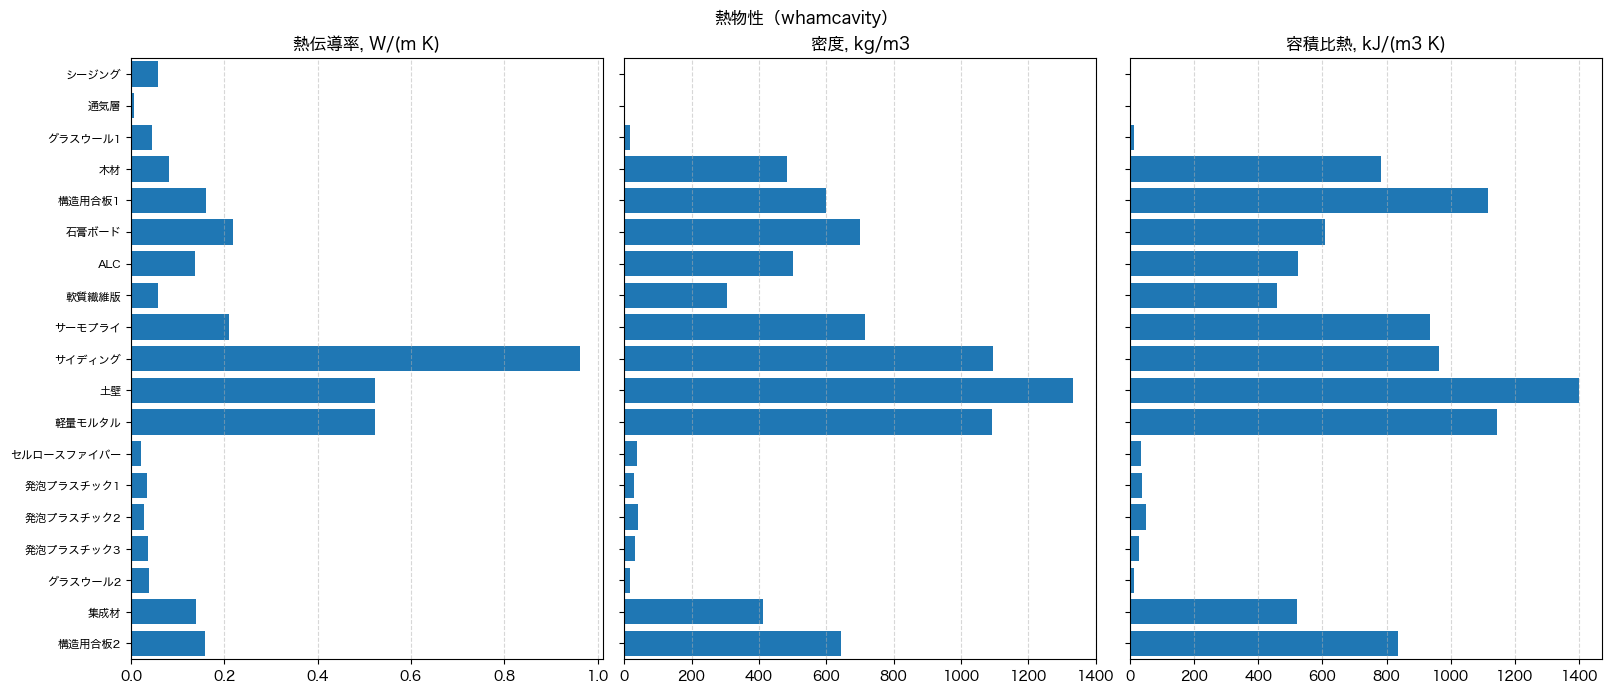

In [7]:
plot_thermal('whamcavity')

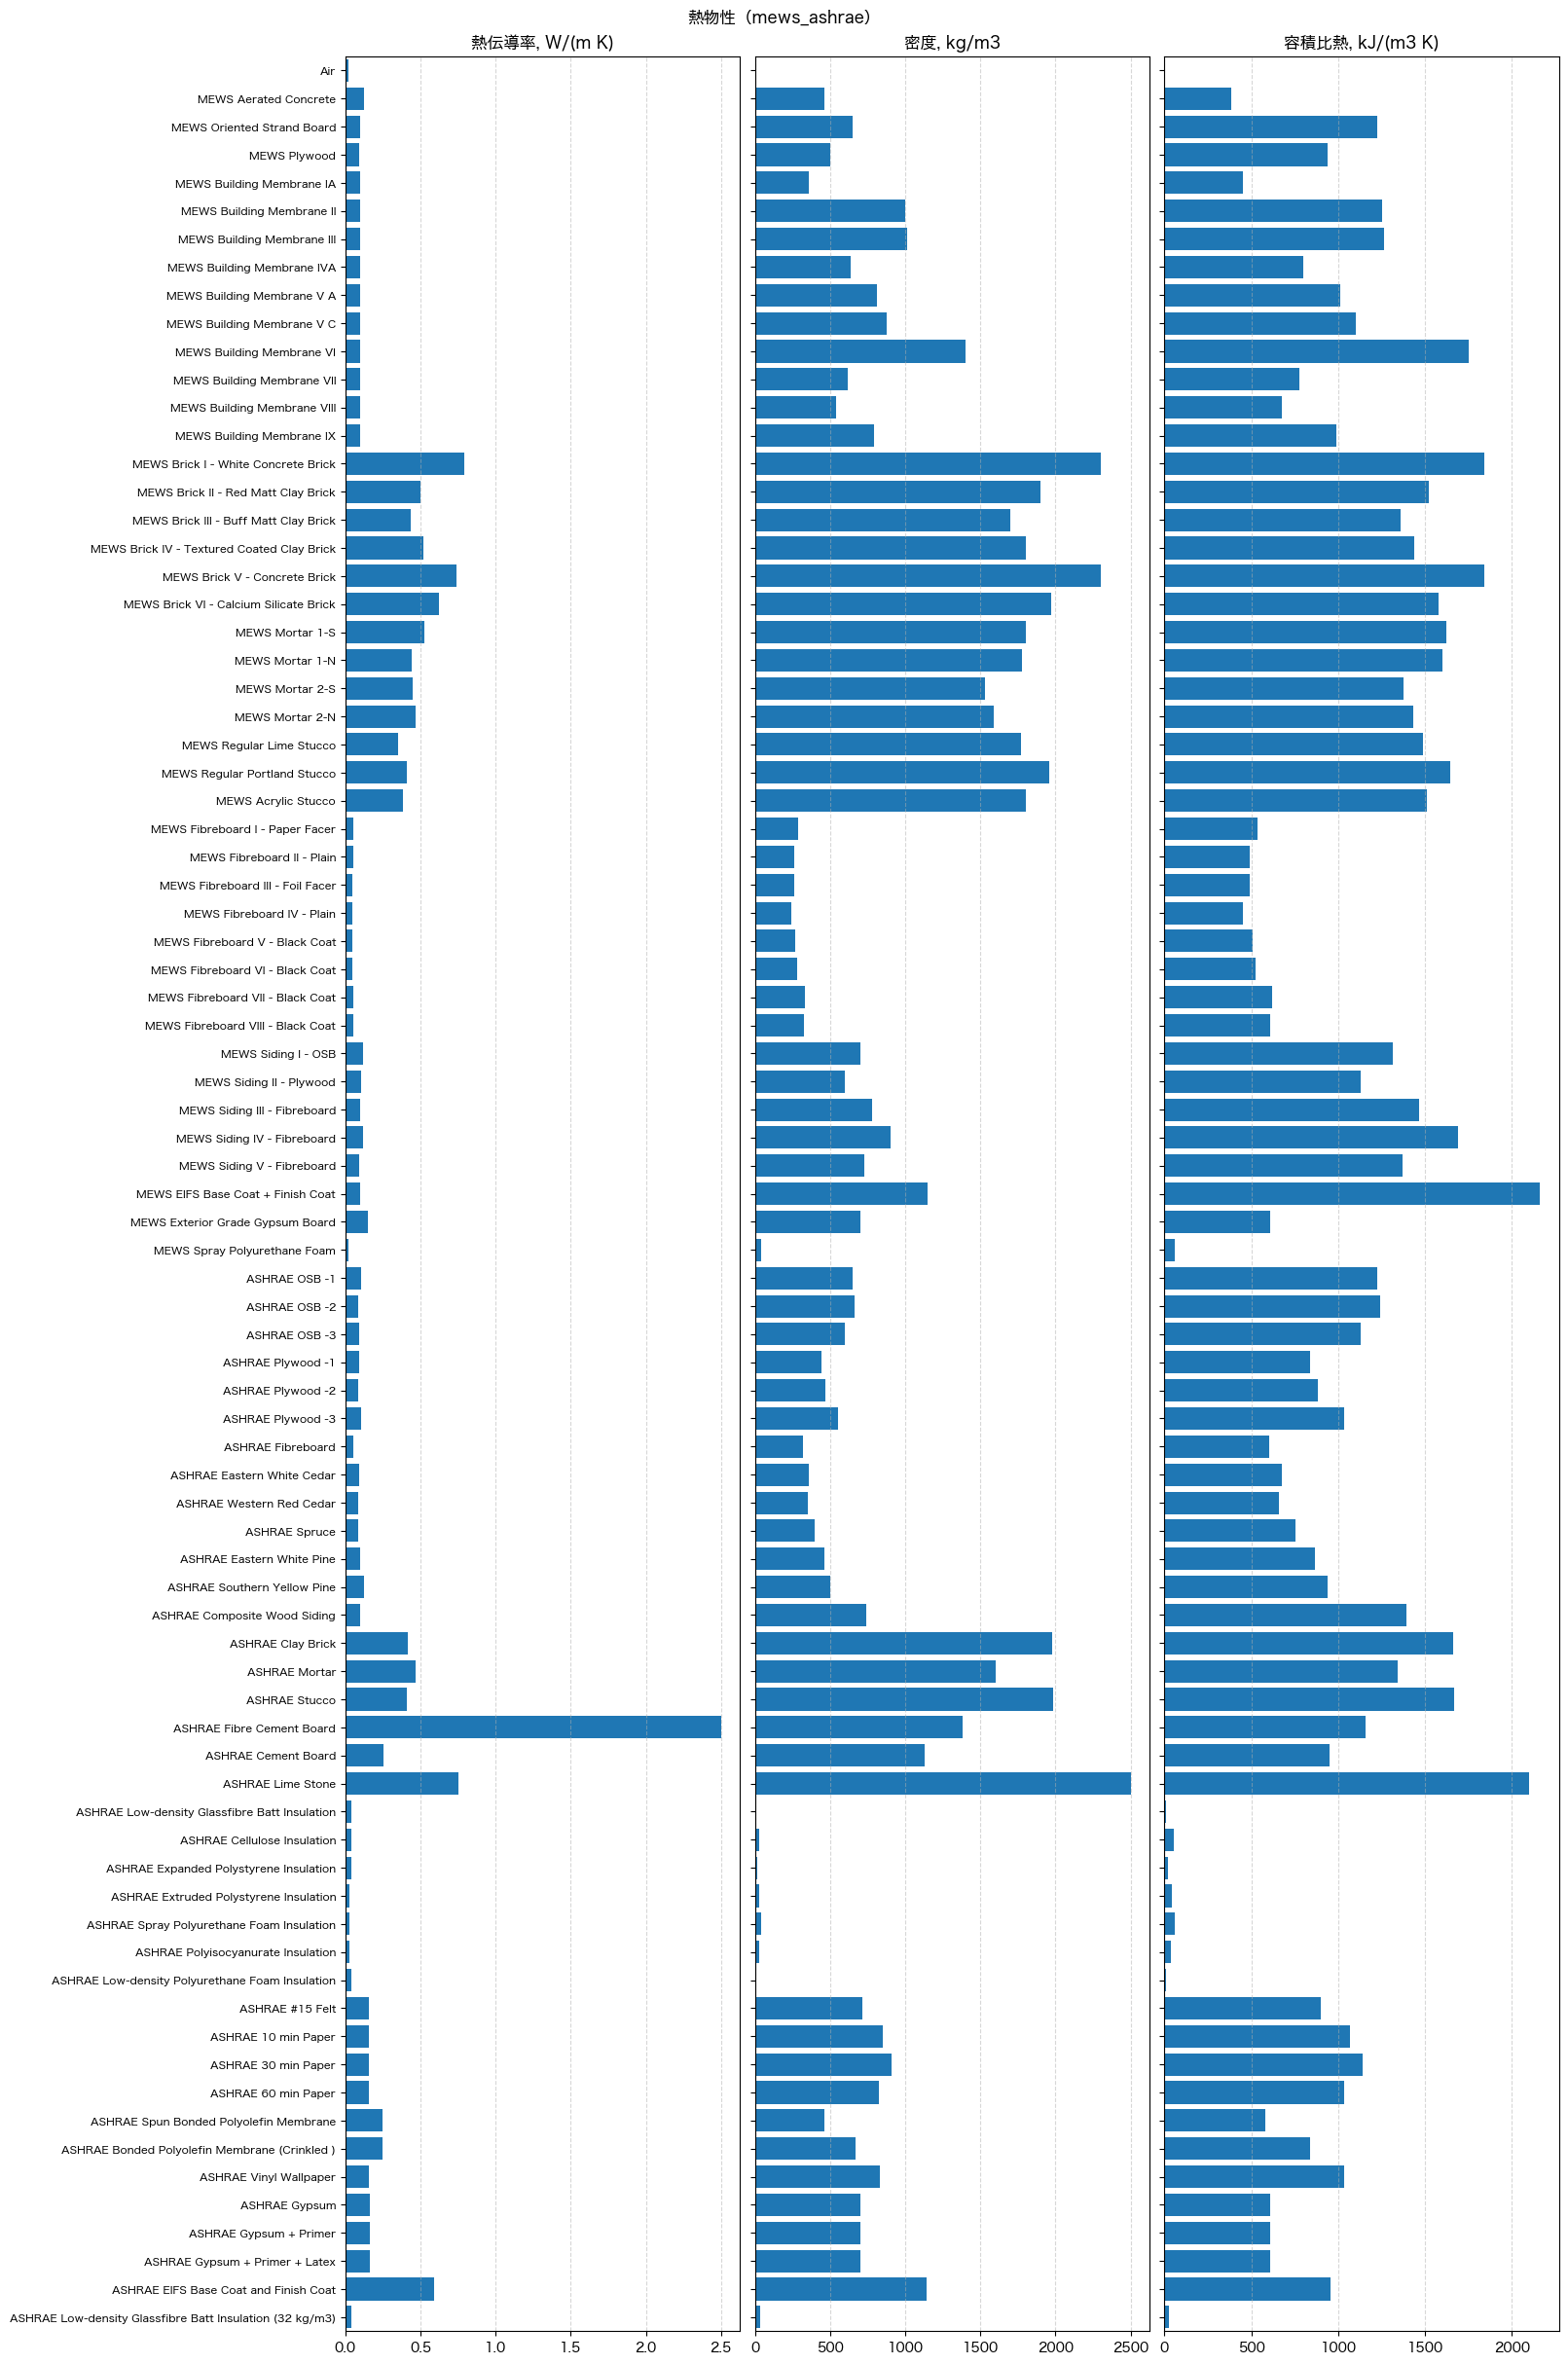

In [8]:
plot_thermal('mews_ashrae')